<a href="https://colab.research.google.com/github/ratheesh0703/Traffic-Conjestion-Prediction/blob/main/traffic_volume.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import zipfile
import os

zip_path = '/content/archive (1).zip'
extract_dir = '/content/metro_traffic'

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_dir)

print("Extracted files:", os.listdir(extract_dir))

Extracted files: ['Test.csv', 'sample_submission.csv', 'Train.csv']


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import os
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

np.random.seed(42)
tf.random.set_seed(42)

# Explicitly load Train.csv which contains the traffic_volume target column
csv_file = '/content/metro_traffic/Train.csv'

df = pd.read_csv(csv_file)
print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())
display(df.head())

Dataset shape: (33750, 15)
Columns: ['date_time', 'is_holiday', 'air_pollution_index', 'humidity', 'wind_speed', 'wind_direction', 'visibility_in_miles', 'dew_point', 'temperature', 'rain_p_h', 'snow_p_h', 'clouds_all', 'weather_type', 'weather_description', 'traffic_volume']


,date_time,is_holiday,air_pollution_index,humidity,wind_speed,wind_direction,visibility_in_miles,dew_point,temperature,rain_p_h,snow_p_h,clouds_all,weather_type,weather_description,traffic_volume
0,2012-10-02 09:00:00,NaN,121,89,2,329,1,1,288.28,0.0,0.0,40,Clouds,scattered clouds,5545
1,2012-10-02 10:00:00,NaN,178,67,3,330,1,1,289.36,0.0,0.0,75,Clouds,broken clouds,4516
2,2012-10-02 11:00:00,NaN,113,66,3,329,2,2,289.58,0.0,0.0,90,Clouds,overcast clouds,4767
3,2012-10-02 12:00:00,NaN,20,66,3,329,5,5,290.13,0.0,0.0,90,Clouds,overcast clouds,5026
4,2012-10-02 13:00:00,NaN,281,65,3,329,7,7,291.14,0.0,0.0,75,Clouds,broken clouds,4918


In [ ]:
df["date_time"] = pd.to_datetime(df["date_time"], errors="coerce")
df = df.dropna(subset=["date_time", "traffic_volume"])
df = df.sort_values("date_time").drop_duplicates("date_time", keep="last").set_index("date_time")

# Map columns to match the Train.csv specific schema
numeric_cols = ["traffic_volume", "temperature", "rain_p_h", "snow_p_h", "clouds_all"]
numeric_cols = [c for c in numeric_cols if c in df.columns]
hourly_num = df[numeric_cols].resample("h").mean()
hourly_num = hourly_num.interpolate(method="time", limit=3, limit_area="inside")

hourly_cat = df.resample("h").last()

# Map weather_main to weather_type
holiday_col = "is_holiday" if "is_holiday" in df.columns else "holiday"
weather_col = "weather_type" if "weather_type" in df.columns else "weather_main"

hourly = hourly_num.join(
    hourly_cat[[holiday_col, weather_col]]
    if all(c in hourly_cat.columns for c in [holiday_col, weather_col])
    else hourly_cat[[c for c in [holiday_col, weather_col] if c in hourly_cat.columns]],
    how="left"
)

# Rename columns back to standard variable naming in the next cells
hourly = hourly.rename(columns={
    "temperature": "temp",
    "rain_p_h": "rain_1h",
    "snow_p_h": "snow_1h",
    holiday_col: "holiday",
    weather_col: "weather_main"
})

if "holiday" in hourly.columns:
    hourly["holiday"] = hourly["holiday"].fillna("None")
if "weather_main" in hourly.columns:
    hourly["weather_main"] = hourly["weather_main"].ffill().bfill()

hourly = hourly.dropna(subset=["traffic_volume"])
groups = hourly.index.to_series().diff().ne(pd.Timedelta(hours=1)).cumsum()
hourly = max((g for _, g in hourly.groupby(groups)), key=len).copy()

print("Consecutive hourly records:", len(hourly))
print("Start:", hourly.index.min())
print("End:", hourly.index.max())

Consecutive hourly records: 7004
Start: 2016-04-27 23:00:00
End: 2017-02-13 18:00:00


In [ ]:
import numpy as np
import pandas as pd

data = hourly.copy()
data["hour"] = data.index.hour
data["day_of_week"] = data.index.dayofweek
data["month"] = data.index.month
data["is_weekend"] = (data.index.dayofweek >= 5).astype(int)

data["hour_sin"] = np.sin(2 * np.pi * data["hour"] / 24)
data["hour_cos"] = np.cos(2 * np.pi * data["hour"] / 24)
data["day_sin"] = np.sin(2 * np.pi * data["day_of_week"] / 7)
data["day_cos"] = np.cos(2 * np.pi * data["day_of_week"] / 7)

if "holiday" in data.columns:
    data["is_holiday"] = (data["holiday"].notna() & data["holiday"].ne("None")).astype(int)

feature_cols = [c for c in [
    "traffic_volume", "temp", "rain_1h", "snow_1h", "clouds_all",
    "hour_sin", "hour_cos", "day_sin", "day_cos", "month", "is_weekend", "is_holiday"
] if c in data.columns]

if "weather_main" in data.columns:
    weather_encoded = pd.get_dummies(data["weather_main"], prefix="weather", dtype=int)
    data = pd.concat([data.drop(columns=["weather_main"]), weather_encoded], axis=1)
    feature_cols += weather_encoded.columns.tolist()

X_raw = data[feature_cols].astype(float).values
y_raw = data["traffic_volume"].astype(float).values

print("Number of observations:", len(data))
print("Number of input features:", X_raw.shape[1])
print("Features:", feature_cols)

Number of observations: 7004
Number of input features: 23
Features: ['traffic_volume', 'temp', 'rain_1h', 'snow_1h', 'clouds_all', 'hour_sin', 'hour_cos', 'day_sin', 'day_cos', 'month', 'is_weekend', 'is_holiday', 'weather_Clear', 'weather_Clouds', 'weather_Drizzle', 'weather_Fog', 'weather_Haze', 'weather_Mist', 'weather_Rain', 'weather_Smoke', 'weather_Snow', 'weather_Squall', 'weather_Thunderstorm']


In [ ]:
from sklearn.preprocessing import StandardScaler
import numpy as np

WINDOW = 24
n = len(data)
train_end = int(n * 0.70)
val_end = int(n * 0.85)

x_scaler = StandardScaler()
y_scaler = StandardScaler()

x_scaler.fit(X_raw[:train_end])
y_scaler.fit(y_raw[:train_end].reshape(-1, 1))

X_scaled = x_scaler.transform(X_raw)
y_scaled = y_scaler.transform(y_raw.reshape(-1, 1)).flatten()

X_seq, y_seq, target_indices = [], [], []
for i in range(WINDOW, n):
    X_seq.append(X_scaled[i-WINDOW:i])
    y_seq.append(y_scaled[i])
    target_indices.append(i)

X_seq = np.asarray(X_seq, dtype=np.float32)
y_seq = np.asarray(y_seq, dtype=np.float32)
target_indices = np.asarray(target_indices)

train_mask = target_indices < train_end
val_mask = (target_indices >= train_end) & (target_indices < val_end)
test_mask = target_indices >= val_end

X_train, y_train = X_seq[train_mask], y_seq[train_mask]
X_val, y_val = X_seq[val_mask], y_seq[val_mask]
X_test, y_test = X_seq[test_mask], y_seq[test_mask]

print("Training shape:", X_train.shape)
print("Validation shape:", X_val.shape)
print("Testing shape:", X_test.shape)
print("Input shape:", X_train.shape[1:])

Training shape: (4878, 24, 23)
Validation shape: (1051, 24, 23)
Testing shape: (1051, 24, 23)
Input shape: (24, 23)


In [ ]:
import tensorflow as tf

model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(WINDOW, X_train.shape[2])),
    tf.keras.layers.LSTM(64, return_sequences=True),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.LSTM(32),
    tf.keras.layers.Dense(16, activation="relu"),
    tf.keras.layers.Dense(1)
])

model.compile(optimizer="adam", loss="mse", metrics=["mae"])
model.summary()

early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=5, restore_best_weights=True
)

history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=25,
    batch_size=64,
    shuffle=False,
    callbacks=[early_stop],
    verbose=1
)

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_6 (LSTM)                   │ (None, 24, 64)         │        22,528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 24, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_7 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 35,489 (138.63 KB)

 Trainable params: 35,489 (138.63 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/25
77/77 ━━━━━━━━━━━━━━━━━━━━ 8s 36ms/step - loss: 0.4303 - mae: 0.5037 - val_loss: 0.7483 - val_mae: 0.6740
Epoch 2/25
77/77 ━━━━━━━━━━━━━━━━━━━━ 2s 31ms/step - loss: 0.1415 - mae: 0.2758 - val_loss: 0.6430 - val_mae: 0.6122
Epoch 3/25
77/77 ━━━━━━━━━━━━━━━━━━━━ 2s 30ms/step - loss: 0.0945 - mae: 0.2193 - val_loss: 0.6339 - val_mae: 0.6021
Epoch 4/25
77/77 ━━━━━━━━━━━━━━━━━━━━ 4s 49ms/step - loss: 0.0758 - mae: 0.1974 - val_loss: 0.6250 - val_mae: 0.5777
Epoch 5/25
77/77 ━━━━━━━━━━━━━━━━━━━━ 2s 30ms/step - loss: 0.0629 - mae: 0.1805 - val_loss: 0.6128 - val_mae: 0.5635
Epoch 6/25
77/77 ━━━━━━━━━━━━━━━━━━━━ 3s 30ms/step - loss: 0.0573 - mae: 0.1728 - val_loss: 0.6073 - val_mae: 0.5575
Epoch 7/25
77/77 ━━━━━━━━━━━━━━━━━━━━ 2s 30ms/step - loss: 0.0518 - mae: 0.1665 - val_loss: 0.5981 - val_mae: 0.5482
Epoch 8/25
77/77 ━━━━━━━━━━━━━━━━━━━━ 2s 31ms/step - loss: 0.0473 - mae: 0.1593 - val_loss: 0.6081 - val_mae: 0.5561
Epoch 9/25
77/77 ━━━━━━━━━━━━━━━━━━━━ 4s 46ms/step - loss: 0.043

In [ ]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error

pred_scaled = model.predict(X_test, verbose=0).reshape(-1, 1)
y_pred = y_scaler.inverse_transform(pred_scaled).flatten()
y_actual = y_raw[target_indices[test_mask]]

mae = mean_absolute_error(y_actual, y_pred)
rmse = np.sqrt(mean_squared_error(y_actual, y_pred))

print(f"Test MAE:  {mae:.2f} vehicles/hour")
print(f"Test RMSE: {rmse:.2f} vehicles/hour")

Test MAE:  667.72 vehicles/hour
Test RMSE: 973.70 vehicles/hour


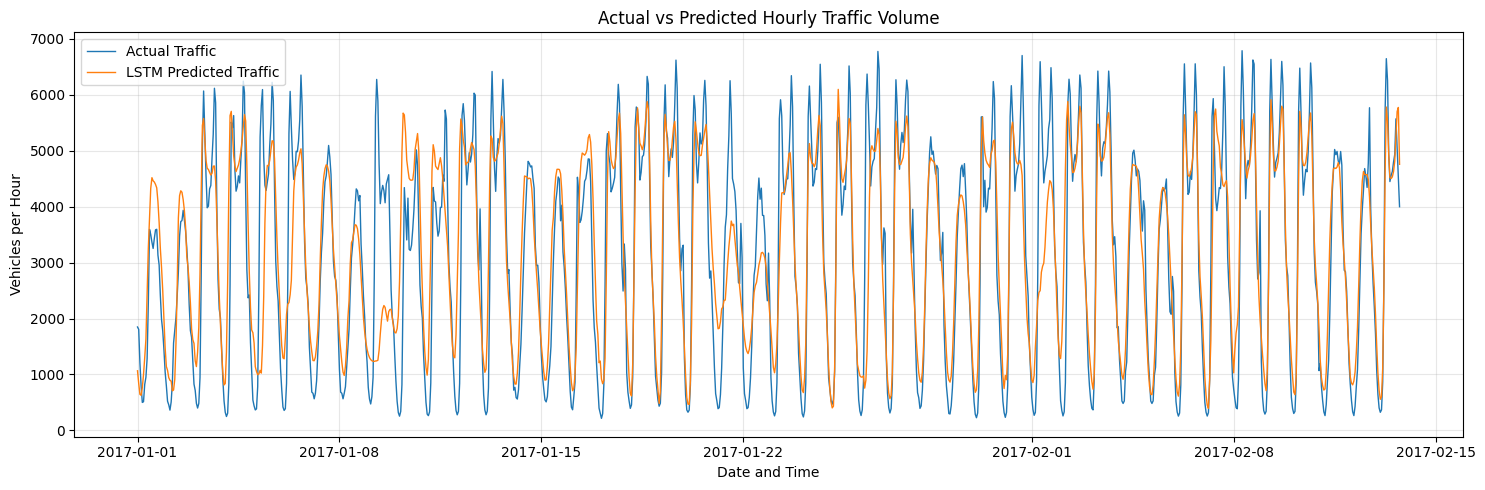

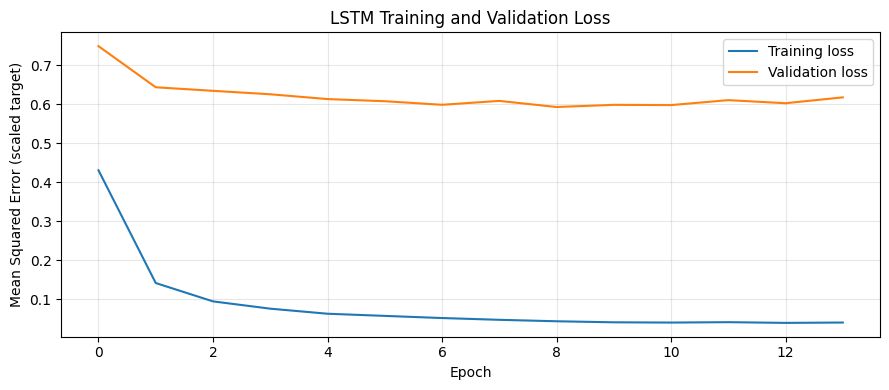

In [ ]:
test_dates = data.index[target_indices[test_mask]]

plt.figure(figsize=(15, 5))
plt.plot(
    test_dates, y_actual,
    label="Actual Traffic",
    linewidth=1
)
plt.plot(
    test_dates, y_pred,
    label="LSTM Predicted Traffic",
    linewidth=1
)

plt.title("Actual vs Predicted Hourly Traffic Volume")
plt.xlabel("Date and Time")
plt.ylabel("Vehicles per Hour")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 4))
plt.plot(history.history["loss"], label="Training loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.title("LSTM Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error (scaled target)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

High-traffic threshold: 5013 vehicles/hour

Predicted high-traffic hours:
          timestamp  predicted_volume
2017-01-03 07:00:00       5707.294922
2017-01-03 08:00:00       5415.954102
2017-01-03 13:00:00       5179.127441
2017-01-03 14:00:00       5477.663086
2017-01-03 15:00:00       5790.583496
2017-01-03 16:00:00       5830.497070
2017-01-03 17:00:00       5420.187988
2017-01-04 06:00:00       5665.945801
2017-01-04 07:00:00       5441.333008
2017-01-04 14:00:00       5039.923340
2017-01-04 15:00:00       5352.802246
2017-01-04 16:00:00       5734.588379
2017-01-04 17:00:00       5827.670898
2017-01-04 18:00:00       5171.038086
2017-01-05 09:00:00       5156.109863


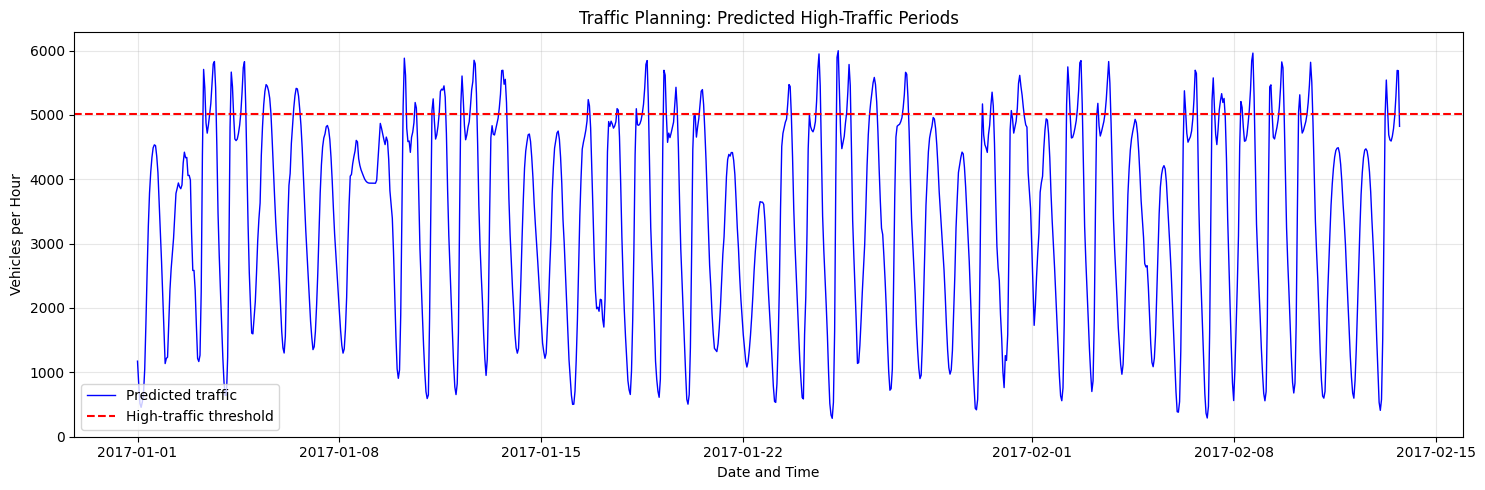

In [ ]:
threshold = np.percentile(y_raw[:train_end], 80)

results = pd.DataFrame({
    "timestamp": test_dates,
    "actual_volume": y_actual,
    "predicted_volume": y_pred
})

results["predicted_high_traffic"] = (
    results["predicted_volume"] >= threshold
)

print(f"High-traffic threshold: {threshold:.0f} vehicles/hour")

print("\nPredicted high-traffic hours:")
print(
    results.loc[
        results["predicted_high_traffic"],
        ["timestamp", "predicted_volume"]
    ].head(15).to_string(index=False)
)

results.to_csv(
    "traffic_forecast_results.csv",
    index=False
)

plt.figure(figsize=(15, 5))
plt.plot(
    results["timestamp"],
    results["predicted_volume"],
    label="Predicted traffic",
    color="blue",
    linewidth=1
)
plt.axhline(
    threshold,
    color="red",
    linestyle="--",
    label="High-traffic threshold"
)
plt.title("Traffic Planning: Predicted High-Traffic Periods")
plt.xlabel("Date and Time")
plt.ylabel("Vehicles per Hour")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()